# Allocation: Vanilla and Trend-Overlay Comparison

Rebuilds the saved sweep portfolios from their weights and compares each with and without the SPI trend overlay: ranked tables, heatmaps, full reports for single runs, and summary exports. Needs the output of a model sweep notebook in `ml_stock_selection/sweep_results_*`.


In [ ]:
import os, sys, glob, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start=None):
    """Walk up from the notebook folder to the repository root."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'framework').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the repository root (folder containing framework/).')

REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / 'data'
for module_dir in ('framework', 'signals', 'data_utils'):
    if str(REPO_ROOT / module_dir) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT / module_dir))
missing = [f for f in ['market_data.parquet', 'jkp_data.parquet', 'spi_index.csv', 'IRSTCI01CHM156N.csv'] if not (DATA_PATH / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_PATH}: {missing}. See data/README.md.')

from helper_functions import load_data_spi, align_market_data_with_jkp_data
from backtesting.backtest_data import BacktestData
from backtesting.strategy import Strategy
from backtesting.portfolio import Portfolio
import swiss_rf as srf

market_data = pd.read_parquet(REPO_ROOT/'data'/'market_data.parquet')
jkp_data    = pd.read_parquet(REPO_ROOT/'data'/'jkp_data.parquet')
spi         = load_data_spi(path=str(REPO_ROOT/'data')+os.sep)
market_data_ffill, jkp_data = align_market_data_with_jkp_data(market_data=market_data, jkp_data=jkp_data)
data = BacktestData()
data.market_data = market_data_ffill; data.jkp_data = jkp_data; data.bm_series = spi

FIXED_COSTS, VARIABLE_COSTS = 0.01, 0.002

# --- locate the sweep folder (nested: SWEEP_DIR/<run_id>/weights.parquet) ---
SWEEP_DIR = 'sweep_results_enet'              # edit if needed
if not glob.glob(os.path.join(SWEEP_DIR, '*', 'weights.parquet')):
    hit = glob.glob(os.path.join('**', 'ra1_tp0.0_ub0.1', 'weights.parquet'), recursive=True)
    assert hit, 'Could not find <run_id>/weights.parquet anywhere under cwd'
    SWEEP_DIR = os.path.dirname(os.path.dirname(hit[0]))
print('SWEEP_DIR =', SWEEP_DIR)

RF_CSV = str(DATA_PATH / 'IRSTCI01CHM156N.csv')

# --- shared daily series ---
return_series_all = data.get_return_series(weekdays_only=False)
return_series_all.index = pd.to_datetime(return_series_all.index)
RF_FULL = srf.build_daily_rf(RF_CSV, return_series_all.index)
_sp = (1 + data.bm_series).cumprod()
OVERLAY = (_sp > _sp.rolling(250).mean()).astype(float).shift(1).fillna(0.0)

def _strategy_from_weights(rid):
    wdf = pd.read_parquet(os.path.join(SWEEP_DIR, rid, 'weights.parquet'))
    wdf.index = pd.to_datetime(wdf.index).strftime('%Y-%m-%d')
    wdf = wdf.sort_index()
    keep = [c for c in wdf.columns if c in return_series_all.columns]
    wdf = wdf[keep]
    ports = [Portfolio(rebalancing_date=d, weights=row.dropna().to_dict()) for d, row in wdf.iterrows()]
    return Strategy(ports), wdf

def build_run(rid):
    """Rebuild vanilla + overlay daily net/gross from saved weights (no optimisation)."""
    strat, wdf = _strategy_from_weights(rid)
    g  = strat.simulate(return_series=return_series_all, fc=0, vc=0)
    idx = g.index
    to = strat.turnover(return_series=return_series_all, rescale=False); to.index = pd.to_datetime(to.index)
    vc = (to * VARIABLE_COSTS).reindex(idx).fillna(0.0)
    nd = np.r_[0, (idx[1:] - idx[:-1]).days]
    fc = pd.Series((1 + FIXED_COSTS) ** (nd/252) - 1, index=idx); fc.iloc[0] = 0.0
    ntr = g - vc - fc
    rf = RF_FULL.reindex(idx).fillna(0.0); e = OVERLAY.reindex(idx).fillna(0.0)
    ret = pd.DataFrame({'net_vanilla': ntr, 'gross_vanilla': g,
                        'net_overlay': e*ntr + (1-e)*rf, 'gross_overlay': e*g + (1-e)*rf})
    w_raw = pd.read_parquet(os.path.join(SWEEP_DIR, rid, 'weights.parquet'))
    return ret, w_raw, to

def _summary_row(net, w, to, rid, n=252):
    cmp = pd.concat({'net': net, 'SPI': data.bm_series}, axis=1).dropna()
    xs = cmp['net'] - RF_FULL.reindex(cmp.index).fillna(0.0)
    cum = (1+cmp['net']).cumprod(); a = (cmp['net']-cmp['SPI']).dropna()
    out = {}
    for part in rid.split('_'):
        for kk, pre in (('risk_aversion','ra'),('turnover_penalty','tp'),('box_upper','ub')):
            if part.startswith(pre): out[kk] = float(part[len(pre):])
    out.update(run_id=rid,
        CAGR=float((1+cmp['net']).prod()**(n/len(cmp))-1),
        Vol=float(cmp['net'].std()*np.sqrt(n)),
        Sharpe=float((xs.mean()*n)/(xs.std()*np.sqrt(n))) if xs.std()>0 else np.nan,
        MaxDD=float((cum/cum.cummax()-1).min()),
        IR=float((a.mean()*n)/(a.std()*np.sqrt(n))) if a.std()>0 else np.nan,
        avg_turnover=float(to.iloc[1:].mean()),
        avg_holdings=float(w.gt(0).sum(axis=1).mean()))
    return out

run_ids = sorted(os.path.basename(os.path.dirname(p))
                 for p in glob.glob(os.path.join(SWEEP_DIR, '*', 'weights.parquet')))
assert run_ids, f'No <run_id>/weights.parquet under {SWEEP_DIR!r}'
print(len(run_ids), 'runs found')

RET, WEI, TURN = {}, {}, {}
rows_v, rows_o = [], []
for rid in run_ids:
    ret, w, to = build_run(rid)
    RET[rid], WEI[rid], TURN[rid] = ret, w, to
    rows_v.append(_summary_row(ret['net_vanilla'], w, to, rid))
    rows_o.append(_summary_row(ret['net_overlay'], w, to, rid))
SUMMARY = {'vanilla': pd.DataFrame(rows_v), 'overlay': pd.DataFrame(rows_o)}
print('Rebuilt vanilla + overlay for', len(run_ids), 'runs from saved weights.')

SWEEP_DIR = sweep_results_enet
64 runs found
Rebuilt vanilla + overlay for 64 runs from saved weights.


Top 10 configurations by net Sharpe (excess over Swiss rf) — VANILLA:


,risk_aversion,turnover_penalty,box_upper,run_id,CAGR,Vol,Sharpe,MaxDD,IR,avg_turnover,avg_holdings
0,200.0,0.5,0.15,ra200_tp0.5_ub0.15,11.48,16.50,0.74,-59.19,0.39,40.38,110.662921
1,10.0,0.0,0.15,ra10_tp0.0_ub0.15,10.98,16.39,0.72,-58.81,0.35,94.02,110.662921
2,1.0,0.5,0.15,ra1_tp0.5_ub0.15,11.09,16.58,0.72,-59.19,0.37,40.18,110.662921
3,10.0,0.5,0.15,ra10_tp0.5_ub0.15,11.09,16.58,0.72,-59.19,0.37,40.19,110.662921
4,50.0,0.5,0.15,ra50_tp0.5_ub0.15,11.09,16.56,0.72,-59.19,0.37,40.17,110.662921
5,200.0,0.5,0.10,ra200_tp0.5_ub0.1,10.51,15.43,0.72,-57.23,0.35,37.23,110.662921
6,200.0,0.0,0.15,ra200_tp0.0_ub0.15,11.00,16.29,0.72,-58.87,0.35,93.79,110.662921
7,1.0,0.0,0.15,ra1_tp0.0_ub0.15,10.98,16.39,0.72,-58.81,0.35,94.02,110.662921
8,50.0,0.0,0.15,ra50_tp0.0_ub0.15,10.92,16.38,0.71,-58.81,0.35,94.01,110.662921
9,1.0,0.5,0.10,ra1_tp0.5_ub0.1,10.30,15.70,0.70,-58.57,0.33,37.14,110.662921


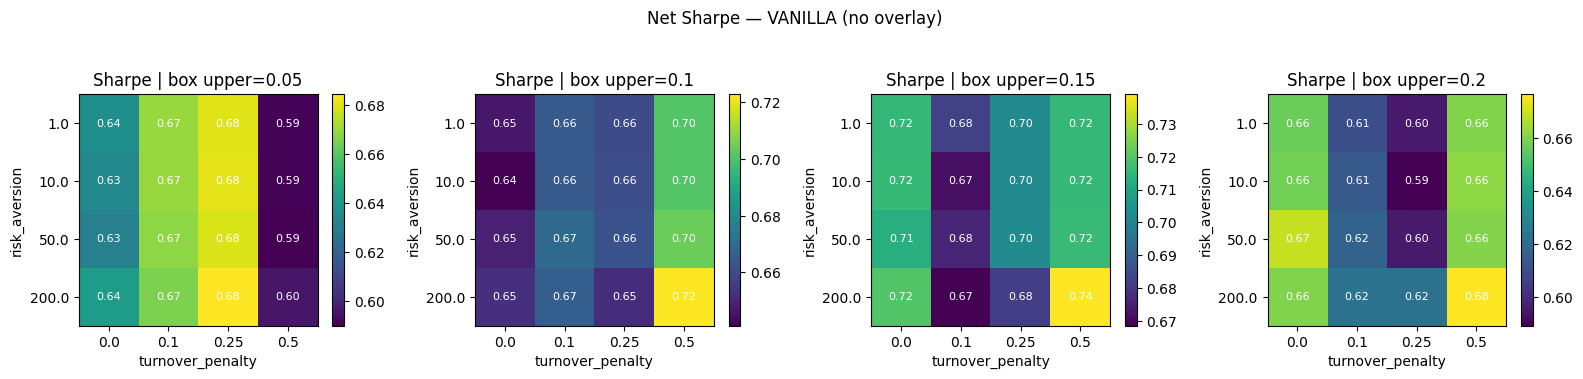

Top 10 configurations by net Sharpe (excess over Swiss rf) — OVERLAY:


,risk_aversion,turnover_penalty,box_upper,run_id,CAGR,Vol,Sharpe,MaxDD,IR,avg_turnover,avg_holdings
0,200.0,0.50,0.15,ra200_tp0.5_ub0.15,14.92,11.19,1.30,-27.57,0.47,40.38,110.662921
1,50.0,0.50,0.10,ra50_tp0.5_ub0.1,13.71,10.48,1.28,-28.46,0.42,37.06,110.662921
2,10.0,0.50,0.10,ra10_tp0.5_ub0.1,13.69,10.51,1.27,-28.45,0.41,37.15,110.662921
3,10.0,0.25,0.15,ra10_tp0.25_ub0.15,14.61,11.24,1.27,-34.07,0.45,57.87,110.662921
4,200.0,0.50,0.10,ra200_tp0.5_ub0.1,13.50,10.36,1.27,-28.34,0.40,37.23,110.662921
5,50.0,0.25,0.15,ra50_tp0.25_ub0.15,14.63,11.23,1.27,-34.06,0.45,57.90,110.662921
6,1.0,0.25,0.15,ra1_tp0.25_ub0.15,14.62,11.24,1.27,-34.07,0.45,57.86,110.662921
7,1.0,0.50,0.10,ra1_tp0.5_ub0.1,13.69,10.51,1.27,-28.45,0.41,37.14,110.662921
8,10.0,0.50,0.15,ra10_tp0.5_ub0.15,14.52,11.26,1.26,-27.19,0.45,40.19,110.662921
9,1.0,0.50,0.15,ra1_tp0.5_ub0.15,14.52,11.26,1.26,-27.19,0.45,40.18,110.662921


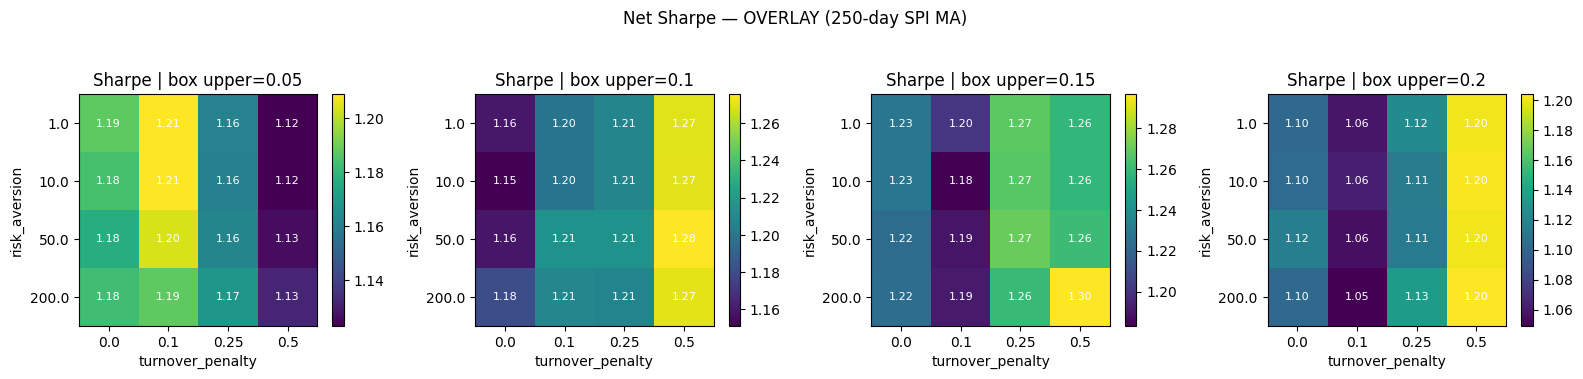

In [12]:
def ranked_and_heatmaps(approach):       # 'vanilla' or 'overlay'
    summary = SUMMARY[approach]
    disp = summary.copy()
    for c in ['CAGR', 'Vol', 'MaxDD', 'avg_turnover']:
        disp[c] = (disp[c] * 100).round(2)
    disp[['Sharpe', 'IR']] = disp[['Sharpe', 'IR']].round(2)
    print(f'Top 10 configurations by net Sharpe (excess over Swiss rf) — {approach.upper()}:')
    display(disp.sort_values('Sharpe', ascending=False).head(10).reset_index(drop=True))

    ubs = sorted(summary['box_upper'].unique())
    fig, ax = plt.subplots(1, len(ubs), figsize=(4*len(ubs), 3.6), squeeze=False)
    for j, ub in enumerate(ubs):
        piv = summary[summary.box_upper == ub].pivot(index='risk_aversion',
                                                     columns='turnover_penalty', values='Sharpe')
        im = ax[0][j].imshow(piv.values, aspect='auto', cmap='viridis')
        ax[0][j].set_xticks(range(len(piv.columns))); ax[0][j].set_xticklabels(piv.columns)
        ax[0][j].set_yticks(range(len(piv.index)));   ax[0][j].set_yticklabels(piv.index)
        ax[0][j].set_xlabel('turnover_penalty'); ax[0][j].set_ylabel('risk_aversion')
        ax[0][j].set_title(f'Sharpe | box upper={ub}')
        for (yi, xi), v in np.ndenumerate(piv.values):
            if np.isfinite(v): ax[0][j].text(xi, yi, f'{v:.2f}', ha='center', va='center', color='w', fontsize=8)
        fig.colorbar(im, ax=ax[0][j])
    title = 'VANILLA (no overlay)' if approach == 'vanilla' else 'OVERLAY (250-day SPI MA)'
    fig.suptitle(f'Net Sharpe — {title}', y=1.04)
    plt.tight_layout(); plt.show()

ranked_and_heatmaps('vanilla')
ranked_and_heatmaps('overlay')

Report for run: ra200_tp0.5_ub0.15


CAGR%    IR  MaxDD%  Sharpe   Vol%
Full sample  Vanilla net  11.48  0.39  -59.19    0.74  16.50
             Overlay net  14.92  0.47  -27.57    1.30  11.19
             SPI           5.56   NaN  -53.25    0.41  16.47
GFC 2007-09  Vanilla net -42.56 -0.58  -59.19   -2.27  23.76
             Overlay net   2.08  1.51   -4.53    0.24   2.87
             SPI         -37.04   NaN  -51.79   -1.49  29.14
Bull 2009-15 Vanilla net  17.79  0.14  -34.43    1.21  14.46
             Overlay net  18.13  0.12  -14.63    1.53  11.41
             SPI          15.59   NaN  -28.23    1.05  15.01
COVID 2020   Vanilla net -97.14 -2.31  -31.60   -7.31  46.73
             Overlay net -66.71  3.74  -10.61   -5.84  18.33
             SPI         -94.91   NaN  -26.33   -5.96  47.64
2022 selloff Vanilla net -27.94 -0.89  -38.56   -1.15  25.44
             Overlay net -20.23 -0.37  -20.98   -2.11  10.29
             SPI         -15.85   NaN  -21.70   -0.95  16.39
Last 5 years Vanilla net   4.34  0.02  -39.24    0.33  19.67
             Overlay net   3.67 -0.09  -27.57    0.36  13.31
             SPI           4.93   NaN  -26.33    0.42  14.59

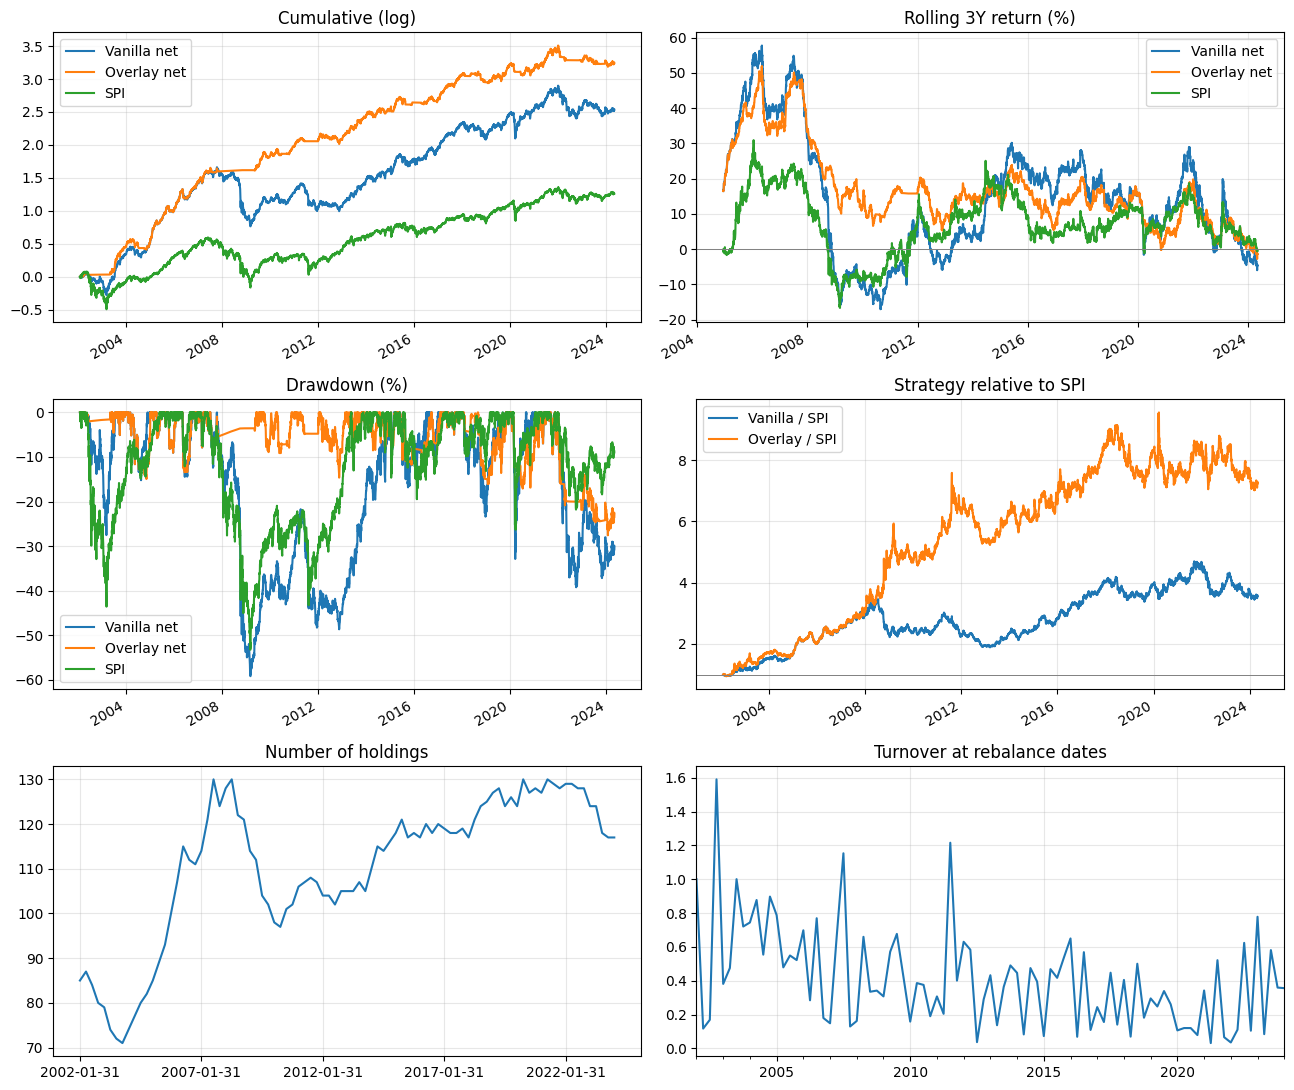

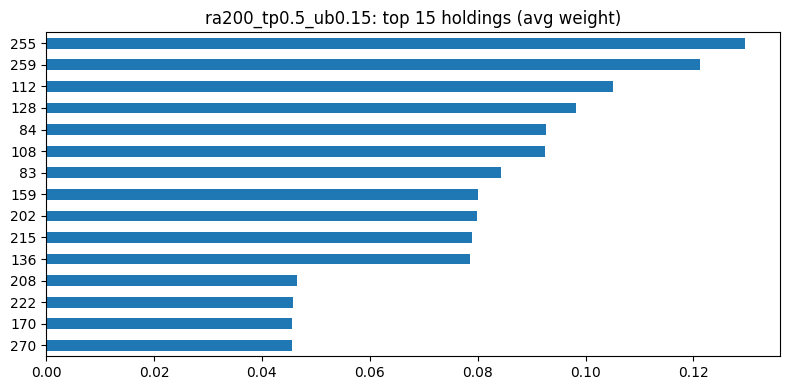

In [13]:
def report_run_both(run_id=None, rank_by='overlay'):
    if run_id is None:
        run_id = SUMMARY[rank_by].sort_values('Sharpe', ascending=False).iloc[0]['run_id']
    ret, w, to = RET[run_id], WEI[run_id], TURN[run_id]
    cmp = pd.concat({'Vanilla net': ret['net_vanilla'],
                     'Overlay net': ret['net_overlay'],
                     'SPI':         data.bm_series}, axis=1).dropna()
    rf  = RF_FULL.reindex(cmp.index).fillna(0.0)
    print('Report for run:', run_id)

    def st(r, bm=None, n=252):
        r = r.dropna()
        xs = r - rf.reindex(r.index).fillna(0.0)
        cum = (1 + r).cumprod()
        o = {'CAGR%': ((1+r).prod()**(n/len(r))-1)*100, 'Vol%': r.std()*np.sqrt(n)*100,
             'Sharpe': (xs.mean()*n)/(xs.std()*np.sqrt(n)) if xs.std() > 0 else np.nan,
             'MaxDD%': (cum/cum.cummax()-1).min()*100}
        if bm is not None:
            a = (r - bm.reindex(r.index)).dropna()
            o['IR'] = (a.mean()*n)/(a.std()*np.sqrt(n)) if a.std() > 0 else np.nan
        return pd.Series(o)

    periods = {'Full sample': (cmp.index.min(), cmp.index.max()),
               'GFC 2007-09': ('2007-10-01', '2009-03-09'),
               'Bull 2009-15': ('2009-03-10', '2015-04-30'),
               'COVID 2020':   ('2020-02-19', '2020-03-23'),
               '2022 selloff': ('2022-01-01', '2022-12-31'),
               'Last 5 years': (cmp.index.max() - pd.DateOffset(years=5), cmp.index.max())}
    rows = {}
    for nm, (s0, e0) in periods.items():
        sub = cmp.loc[s0:e0]
        if len(sub) < 20: continue
        rows[(nm, 'Vanilla net')] = st(sub['Vanilla net'], bm=sub['SPI'])
        rows[(nm, 'Overlay net')] = st(sub['Overlay net'], bm=sub['SPI'])
        rows[(nm, 'SPI')]         = st(sub['SPI'])
    display(pd.DataFrame(rows).T.round(2))

    fig, ax = plt.subplots(3, 2, figsize=(13, 11))
    np.log1p(cmp).cumsum().plot(ax=ax[0, 0])
    ax[0, 0].set_title('Cumulative (log)'); ax[0, 0].grid(alpha=.3)
    ((1+cmp).rolling(756).apply(lambda x: x.prod()**(252/len(x))-1, raw=True)*100).plot(ax=ax[0, 1])
    ax[0, 1].axhline(0, color='grey', lw=.7); ax[0, 1].set_title('Rolling 3Y return (%)'); ax[0, 1].grid(alpha=.3)
    cmp.apply(lambda r: ((1+r).cumprod()/(1+r).cumprod().cummax()-1)*100).plot(ax=ax[1, 0])
    ax[1, 0].set_title('Drawdown (%)'); ax[1, 0].grid(alpha=.3)
    ((1+cmp['Vanilla net']).cumprod()/(1+cmp['SPI']).cumprod()).plot(ax=ax[1, 1], label='Vanilla / SPI')
    ((1+cmp['Overlay net']).cumprod()/(1+cmp['SPI']).cumprod()).plot(ax=ax[1, 1], label='Overlay / SPI')
    ax[1, 1].axhline(1, color='grey', lw=.7); ax[1, 1].legend()
    ax[1, 1].set_title('Strategy relative to SPI'); ax[1, 1].grid(alpha=.3)
    w.gt(0).sum(axis=1).plot(ax=ax[2, 0], title='Number of holdings'); ax[2, 0].grid(alpha=.3)
    to.plot(ax=ax[2, 1], title='Turnover at rebalance dates'); ax[2, 1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

    w.mean().sort_values(ascending=False).head(15).iloc[::-1].plot(
        kind='barh', figsize=(8, 4), title=f'{run_id}: top 15 holdings (avg weight)')
    plt.tight_layout(); plt.show()

report_run_both()                     # best overlay run; or report_run_both('ra10_tp0.25_ub0.1')

In [14]:
import matplotlib
OUT = os.path.join(SWEEP_DIR, 'report_assets'); os.makedirs(OUT, exist_ok=True)

# --- summary tables: both approaches, all 64 runs ---
SUMMARY['vanilla'].to_csv(os.path.join(OUT, 'summary_vanilla.csv'), index=False)
SUMMARY['overlay'].to_csv(os.path.join(OUT, 'summary_overlay.csv'), index=False)

# --- Sharpe heatmaps per approach ---
def save_heatmaps(approach):
    summary = SUMMARY[approach]
    ubs = sorted(summary['box_upper'].unique())
    fig, ax = plt.subplots(1, len(ubs), figsize=(4*len(ubs), 3.6), squeeze=False)
    for j, ub in enumerate(ubs):
        piv = summary[summary.box_upper==ub].pivot(index='risk_aversion',
                      columns='turnover_penalty', values='Sharpe')
        im = ax[0][j].imshow(piv.values, aspect='auto', cmap='viridis')
        ax[0][j].set_xticks(range(len(piv.columns))); ax[0][j].set_xticklabels(piv.columns)
        ax[0][j].set_yticks(range(len(piv.index)));   ax[0][j].set_yticklabels(piv.index)
        ax[0][j].set_xlabel('turnover_penalty'); ax[0][j].set_ylabel('risk_aversion')
        ax[0][j].set_title(f'box upper={ub}')
        for (yi,xi),v in np.ndenumerate(piv.values):
            if np.isfinite(v): ax[0][j].text(xi,yi,f'{v:.2f}',ha='center',va='center',color='w',fontsize=8)
        fig.colorbar(im, ax=ax[0][j])
    t = 'VANILLA (no overlay)' if approach=='vanilla' else 'OVERLAY (250-day SPI MA)'
    fig.suptitle(f'Net Sharpe — {t}', y=1.04); plt.tight_layout()
    fig.savefig(os.path.join(OUT, f'heatmaps_{approach}.png'), dpi=130, bbox_inches='tight'); plt.close(fig)

save_heatmaps('vanilla'); save_heatmaps('overlay')

# --- per-run: period table (csv) + 6-panel figure + top-15 figure ---
def save_run(run_id):
    ret, w, to = RET[run_id], WEI[run_id], TURN[run_id]
    cmp = pd.concat({'Vanilla net': ret['net_vanilla'], 'Overlay net': ret['net_overlay'],
                     'SPI': data.bm_series}, axis=1).dropna()
    rf = RF_FULL.reindex(cmp.index).fillna(0.0)
    def st(r, bm=None, n=252):
        r = r.dropna(); xs = r - rf.reindex(r.index).fillna(0.0); cum=(1+r).cumprod()
        o = {'CAGR%': ((1+r).prod()**(n/len(r))-1)*100, 'Vol%': r.std()*np.sqrt(n)*100,
             'Sharpe': (xs.mean()*n)/(xs.std()*np.sqrt(n)) if xs.std()>0 else np.nan,
             'MaxDD%': (cum/cum.cummax()-1).min()*100}
        if bm is not None:
            a=(r-bm.reindex(r.index)).dropna(); o['IR']=(a.mean()*n)/(a.std()*np.sqrt(n)) if a.std()>0 else np.nan
        return pd.Series(o)
    periods = {'Full sample': (cmp.index.min(), cmp.index.max()),
               'GFC 2007-09': ('2007-10-01','2009-03-09'), 'Bull 2009-15': ('2009-03-10','2015-04-30'),
               'COVID 2020': ('2020-02-19','2020-03-23'), '2022 selloff': ('2022-01-01','2022-12-31'),
               'Last 5 years': (cmp.index.max()-pd.DateOffset(years=5), cmp.index.max())}
    rows = {}
    for nm,(s0,e0) in periods.items():
        sub = cmp.loc[s0:e0]
        if len(sub) < 20: continue
        rows[(nm,'Vanilla net')] = st(sub['Vanilla net'], bm=sub['SPI'])
        rows[(nm,'Overlay net')] = st(sub['Overlay net'], bm=sub['SPI'])
        rows[(nm,'SPI')]         = st(sub['SPI'])
    pd.DataFrame(rows).T.round(2).to_csv(os.path.join(OUT, f'periods_{run_id}.csv'))

    fig, ax = plt.subplots(3, 2, figsize=(13, 11))
    np.log1p(cmp).cumsum().plot(ax=ax[0,0]); ax[0,0].set_title('Cumulative (log)'); ax[0,0].grid(alpha=.3)
    ((1+cmp).rolling(756).apply(lambda x: x.prod()**(252/len(x))-1, raw=True)*100).plot(ax=ax[0,1])
    ax[0,1].axhline(0,color='grey',lw=.7); ax[0,1].set_title('Rolling 3Y return (%)'); ax[0,1].grid(alpha=.3)
    cmp.apply(lambda r: ((1+r).cumprod()/(1+r).cumprod().cummax()-1)*100).plot(ax=ax[1,0])
    ax[1,0].set_title('Drawdown (%)'); ax[1,0].grid(alpha=.3)
    ((1+cmp['Vanilla net']).cumprod()/(1+cmp['SPI']).cumprod()).plot(ax=ax[1,1], label='Vanilla / SPI')
    ((1+cmp['Overlay net']).cumprod()/(1+cmp['SPI']).cumprod()).plot(ax=ax[1,1], label='Overlay / SPI')
    ax[1,1].axhline(1,color='grey',lw=.7); ax[1,1].legend(); ax[1,1].set_title('Strategy relative to SPI'); ax[1,1].grid(alpha=.3)
    w.gt(0).sum(axis=1).plot(ax=ax[2,0], title='Number of holdings'); ax[2,0].grid(alpha=.3)
    to.plot(ax=ax[2,1], title='Turnover at rebalance dates'); ax[2,1].grid(alpha=.3)
    plt.tight_layout(); fig.savefig(os.path.join(OUT, f'panels_{run_id}.png'), dpi=130, bbox_inches='tight'); plt.close(fig)

    figt, axt = plt.subplots(figsize=(8,4))
    w.mean().sort_values(ascending=False).head(15).iloc[::-1].plot(
        kind='barh', ax=axt, title=f'{run_id}: top 15 holdings (avg weight)')
    plt.tight_layout(); figt.savefig(os.path.join(OUT, f'topweights_{run_id}.png'), dpi=130, bbox_inches='tight'); plt.close(figt)

# best run by each approach + (optionally) all runs
best_v = SUMMARY['vanilla'].sort_values('Sharpe', ascending=False).iloc[0]['run_id']
best_o = SUMMARY['overlay'].sort_values('Sharpe', ascending=False).iloc[0]['run_id']
for rid in {best_v, best_o}:
    save_run(rid)

# also dump the full daily returns of the headline runs so the HTML can replot if needed
for rid in {best_v, best_o}:
    RET[rid].to_parquet(os.path.join(OUT, f'returns_both_{rid}.parquet'))

print('best vanilla run:', best_v, '| best overlay run:', best_o)
print('Saved to', OUT, ':', sorted(os.listdir(OUT)))

best vanilla run: ra200_tp0.5_ub0.15 | best overlay run: ra200_tp0.5_ub0.15
Saved to sweep_results_enet\report_assets : ['heatmaps_overlay.png', 'heatmaps_vanilla.png', 'panels_ra200_tp0.5_ub0.15.png', 'periods_ra200_tp0.5_ub0.15.csv', 'returns_both_ra200_tp0.5_ub0.15.parquet', 'summary_overlay.csv', 'summary_vanilla.csv', 'topweights_ra200_tp0.5_ub0.15.png']
